# Analisis Segmentasi Negara dan Pembangunan Ekonomi
---

## 1. Business Understanding

### 1.1 Latar belakang, masalah, dan solusi
1. **Latar Belakang**: Sebuah lembaga bantuan internasional dan analis kebijakan global ingin membangun sistem kecerdasan buatan berbasis Unsupervised Machine Learning untuk mengelompokkan status sosio-ekonomi dan kesehatan dari berbagai negara di seluruh dunia secara otomatis ke dalam beberapa klaster kelompok pembangunan.
2.**Masalah**:Lembaga tersebut masih melakukan pengelompokan pembangunan secara manual satu per satu yang memakan banyak waktu.
3. **Solusi**: Membuat model *machine learning* dengan algoritma **K-Means++** untuk mengelompokkan status sosio-ekonomi dan kesehatan secara otomatis.

### 1.2 Deskripsi dataset `Country_data`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `country` | `str` | Nama negara (string / teks). |
| `child_mort` | `float64` | Angka kematian anak di bawah usia 5 tahun per 1.000 kelahiran hidup. |
| `exports` | `float64` | Persentase ekspor barang dan jasa terhadap PDB (GDP). |
| `health` | `float64` | Persentase pengeluaran total kesehatan terhadap PDB (GDP). |
| `imports` | `float64` | Persentase impor barang dan jasa terhadap PDB (GDP). |
| `income` | `int64` | Pendapatan bersih per kapita (satuan: USD). |
| `inflation` | `float64` | Tingkat pertumbuhan tahunan total inflasi dari PDB. |
| `life_expec` | `float64` | Rata-rata angka harapan hidup saat lahir (satuan: Tahun). |
| `total_fer` | `float64` | Angka kesuburan total / rata-rata jumlah anak yang dilahirkan oleh seorang wanita. |
| `gdpp` | `int64` | Produk Domestik Bruto per kapita (satuan: USD per orang). |

---
## 2. Data Preparation

### 2.1 Import library

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load dataset

In [2]:
df = pd.read_csv('Country-data.csv')
df.columns = df.columns.str.strip()

### 2.3 Tampilkan data teratas dan data terbawah

In [3]:
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [4]:
df.tail()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
162,Vanuatu,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970
163,Venezuela,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500
164,Vietnam,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310
165,Yemen,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310
166,Zambia,83.1,37.0,5.89,30.9,3280,14.00,52.0,5.40,1460


### 2.4 Tampilkan informasi data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


### 2.5 Memeriksa jumlah data, missing value, dan data duplikat

In [6]:
print(f'Jumlah data: {df.size}')

print(f'\nJumlah missing value: {df.isnull().sum().sum()}')
print(f'---- missing value setiap kolom ---- \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\njumlha data duplikat: {df.duplicated().sum()}')

Jumlah data: 1670

Jumlah missing value: 0
---- missing value setiap kolom ---- 
Series([], dtype: int64)

jumlha data duplikat: 0


---
## 3.Exploratory Data Analysis (EDA)

### 3.1 Menampilkan deskripsi data

In [7]:
df.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


### 3.2 Memeriksa outlier dengan IQR dan Z-Score

In [8]:
outliers = []
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - (1.5 * iqr)
        upper = q3 + (1.5 * iqr)
        mean = df[col].mean()
        median = df[col].median()
        std = df[col].std()
        skew = df[col].skew()
        min = df[col].min()
        max = df[col].max()
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z_score = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standar deviasi': std,
            'kemiringan': skew,
            'min': min,
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': max,
            'batas bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z-Score)': outlier_z_score.shape[0],
        })
        
pd.DataFrame(outliers)

,nama kolom,mean,standar deviasi,kemiringan,min,q1,median,q3,max,batas bawah,batas atas,outlier (IQR),outlier (Z-Score)
0,child_mort,38.270060,40.328931,1.450774,2.6000,8.250,19.30,62.10,208.00,-72.5250,142.8750,4,2
1,exports,41.108976,27.412010,2.445824,0.1090,23.800,35.00,51.35,200.00,-17.5250,92.6750,5,3
2,health,6.815689,2.746837,0.705746,1.8100,4.920,6.32,8.60,17.90,-0.6000,14.1200,2,1
3,imports,46.890215,24.209589,1.905276,0.0659,30.200,43.30,58.75,174.00,-12.6250,101.5750,4,3
4,income,17144.688623,19278.067698,2.231480,609.0000,3355.000,9960.00,22800.00,125000.00,-25812.5000,51967.5000,8,4
5,inflation,7.781832,10.570704,5.154049,-4.2100,1.810,5.39,10.75,104.00,-11.6000,24.1600,5,2
6,life_expec,70.555689,8.893172,-0.970996,32.1000,65.300,73.10,76.80,82.80,48.0500,94.0500,3,1
7,total_fer,2.947964,1.513848,0.967092,1.1500,1.795,2.41,3.88,7.49,-1.3325,7.0075,1,1
8,gdpp,12964.155689,18328.704809,2.218051,231.0000,1330.000,4660.00,14050.00,105000.00,-17750.0000,33130.0000,25,4


### 3.3 Visualisasi outlier dengan boxplot

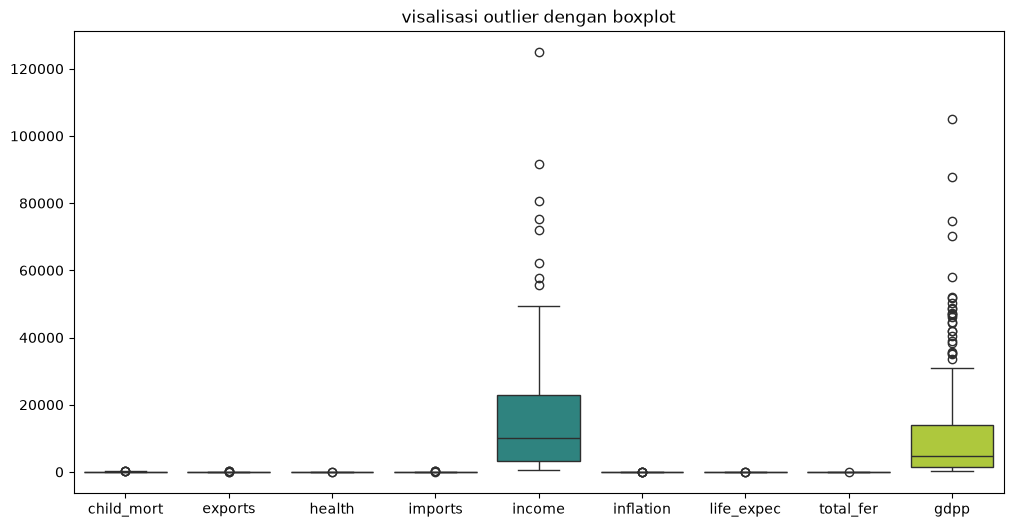

In [9]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, palette='viridis')
plt.title('visalisasi outlier dengan boxplot')
plt.show()

**insight**: Grafik boxplot menunjukan adanya titik titik oulier pada keseluruhan kolom dan terdapat ketimpangan skala yang ekstrem antara fitur `income` dan `gdpp`. oleh karena itu, keputusan sementara pada tahap data preprocessing yaitu dengan membatasi nilai outlier menggunakan metode capping IQR tanpa menghapus baris data dan menyamakan rentan keseluruhan variabel memalui feature scalling.

### 3.4 Visualisasi distribusi data numerik

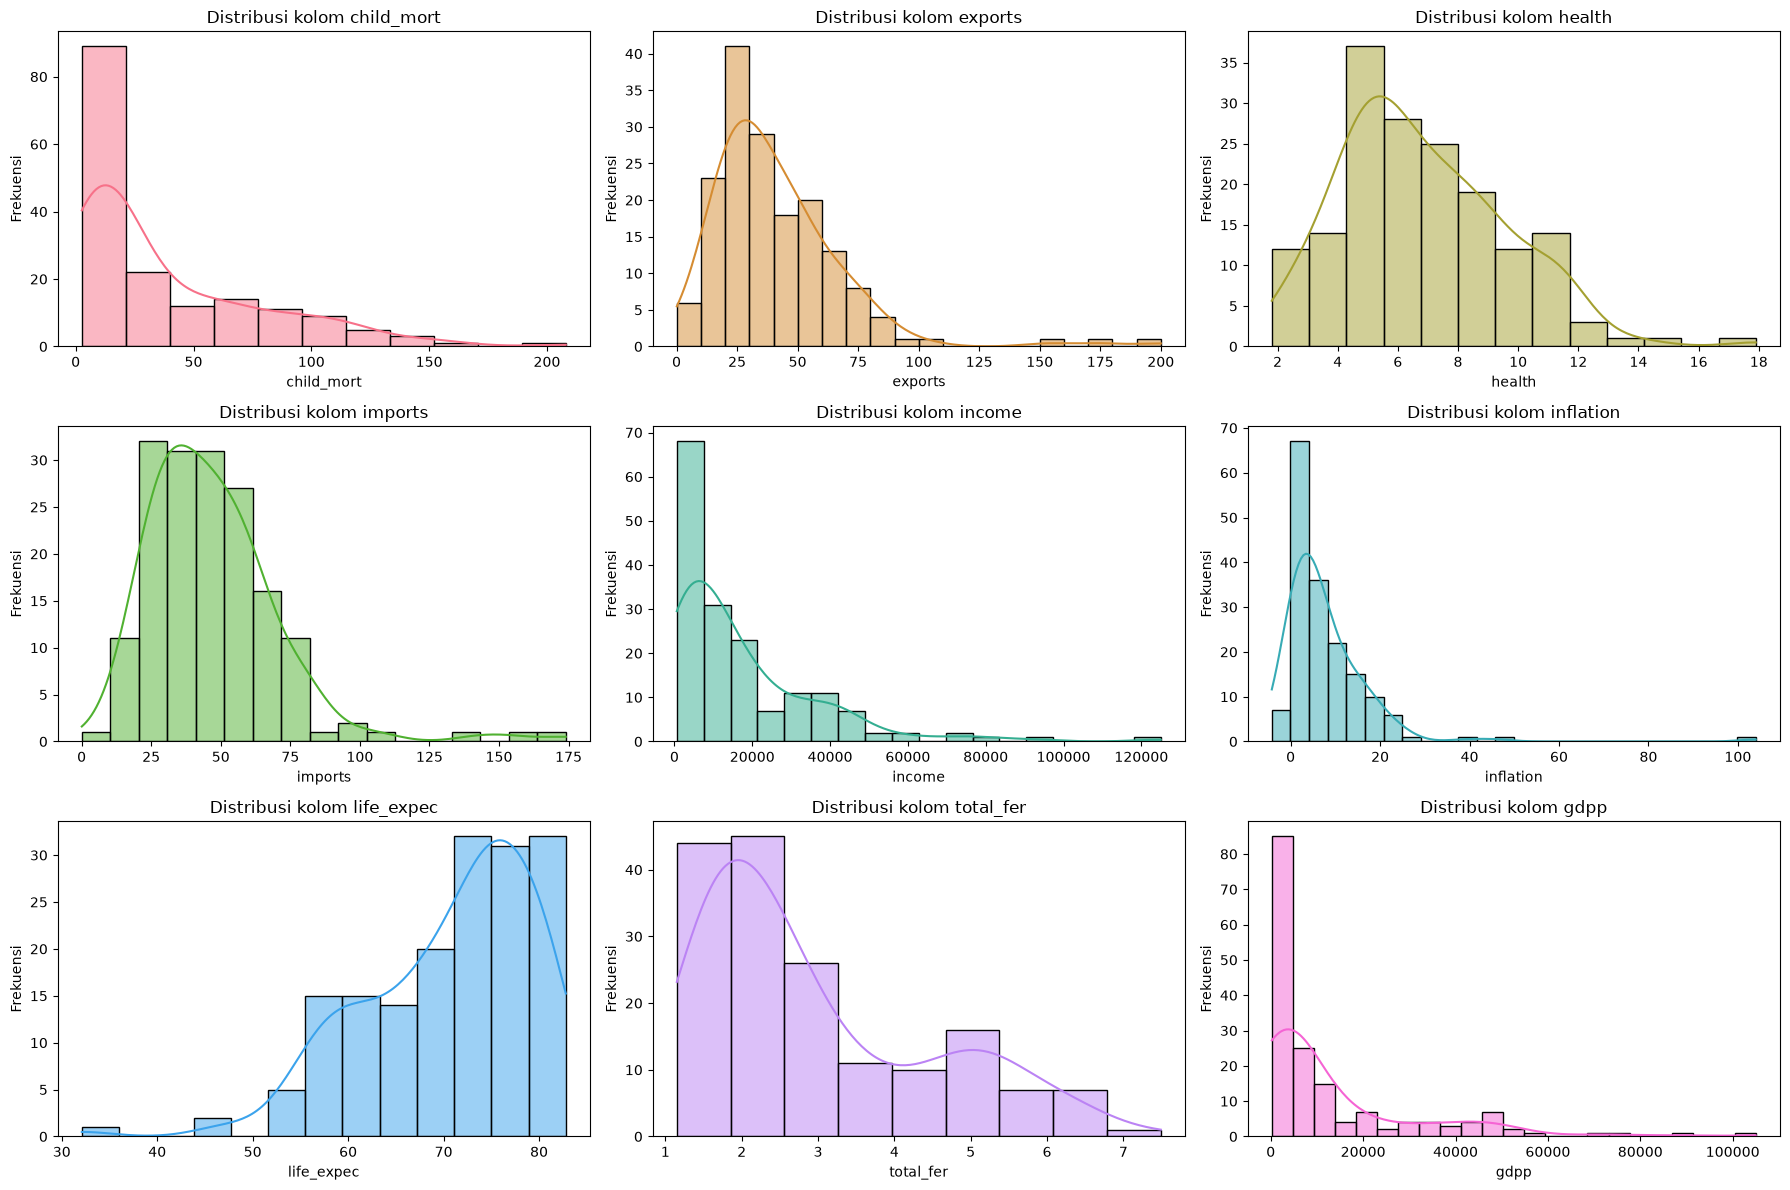

In [10]:
numeric = df.select_dtypes(include=[np.number]).columns.tolist()
n_cols = 3
n_rows = int(np.ceil(len(numeric) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

colors = sns.color_palette('husl', len(numeric))

for i, col in enumerate(numeric):
    sns.histplot(data=df, x=col, kde=True, color=colors[i], ax=axes[i])
    axes[i].set_title(f'Distribusi kolom {col}')
    axes[i].set_ylabel('Frekuensi')
    
for j in range(len(numeric), len(axes)):
    axes[j].set_visible(False)
    
plt.tight_layout()
plt.show()

**insight**: grafik distribusi data menunjukkan bahwa keseluruhan fitur numerik bersifat miring (*skewed*) dan tidak berdistribusi normal.

### 3.5 Analisis korelasi pada kolom numerik

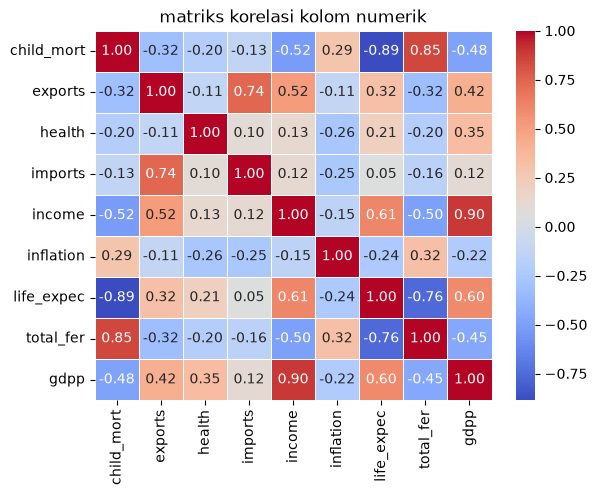

In [11]:
numeric = ['child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']
korelasi = df[numeric].corr(method='pearson')
sns.heatmap(korelasi, cmap='coolwarm', annot=True, fmt=".2f", linewidths=0.5)
plt.title('matriks korelasi kolom numerik')
plt.show()

**Insight**: Mtriks korelasi tersebut menunjukkan adanya korelasi yang kuat pada beberapa kolom, seperti kolom `gdpp` dan `income` (0.90) serta `child_mort` dan `total_fer` (0.85), sedangkan korelasi negatif yang kuat terliaht antara `life_expe` dan `child_mort`(-0.89).

### 3.6 eksplorasi pola sebaran pasangan fitur berkorelasi tinggi

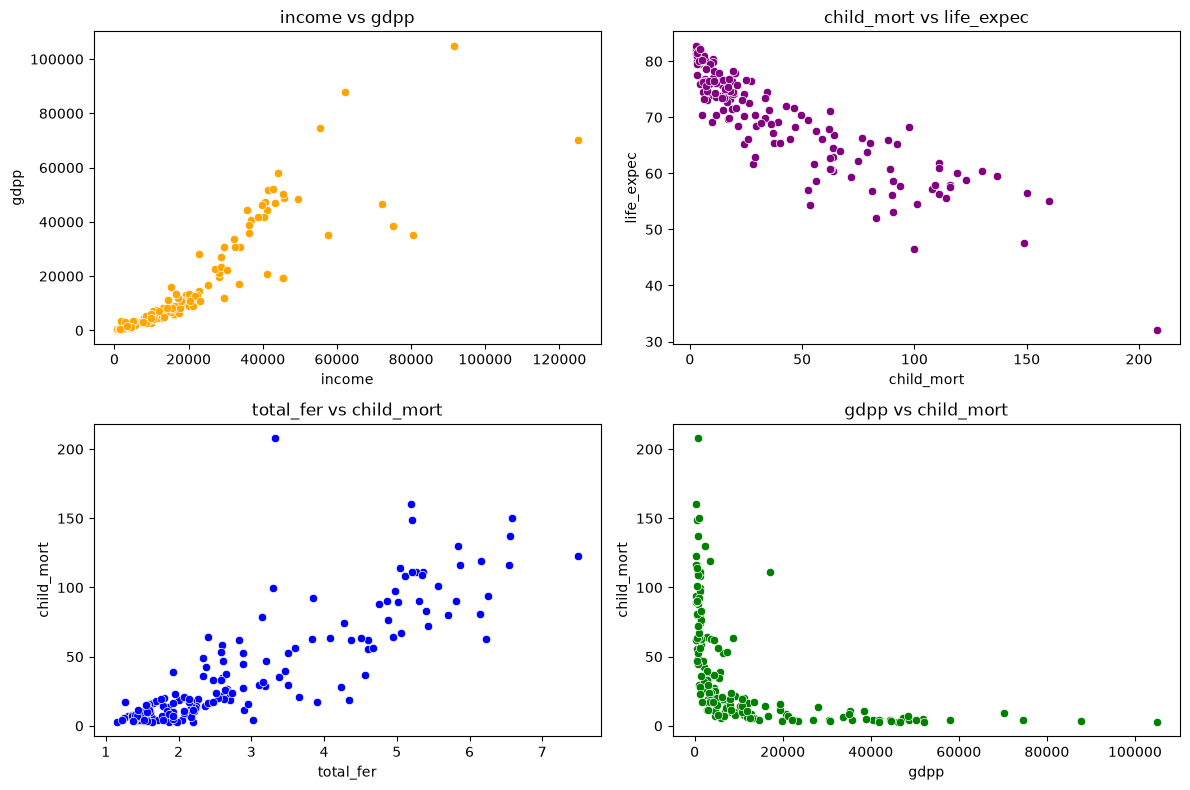

In [12]:
fig, axes = plt.subplots(2,2, figsize=(12,8))

ax1 = axes[0,0]
sns.scatterplot(data=df, x='income', y='gdpp', color='orange', ax=axes[0,0])
ax1.set_title('income vs gdpp')

ax1 = axes[0,1]
sns.scatterplot(data=df, x='child_mort', y='life_expec', color='purple', ax=axes[0,1])
ax1.set_title('child_mort vs life_expec')

ax1 = axes[1,0]
sns.scatterplot(data=df, x='total_fer', y='child_mort', color='blue', ax=axes[1,0])
ax1.set_title('total_fer vs child_mort')

ax1 = axes[1,1]
sns.scatterplot(data=df, x='gdpp', y='child_mort', color='green', ax=axes[1,1])
ax1.set_title('gdpp vs child_mort')

plt.tight_layout()
plt.show()

**Insight**:Visualisasi scatter plot menunjukkan bahwa income dan gdpp berbanding lurus satu sama lain serta berbanding terbalik dengan tingkat kematian anak (child_mort) dan tingkat kelahiran (total_fer). Pola sebaran berbentuk huruf L pada hubungan gdpp dan child_mort memperlihatkan pemisahan antara negara tertinggal, negara berkembang, dan negara maju.

---
## 4. Data Preprocessing

### 4.1 Penangan outlier dengan capping

Penggunaan metode capping berbasis batas IQR diterapkan dibandingkan penghapusan data maupun metode lainnya karena nilai ekstrem pada dataset ini merepresentasikan kondisi nyata negara maju dan negara tertinggal yang harus dipertahankan agar seluruh 167 negara tetap utuh tanpa menarik posisi centroid secara berlebihan.

In [13]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)
    
    df[col] = np.clip(df[col], lower, upper)
    m = df[(df[col] < lower) | (df[col] > upper)]
    print(f'jumlah outlier pada kolom {df[col]} setelah capping: {m.shape[0]}')

print("Jumlah baris setelah capping:", len(df))

jumlah outlier pada kolom 0       90.2
1       16.6
2       27.3
3      119.0
4       10.3
       ...  
162     29.2
163     17.1
164     23.3
165     56.3
166     83.1
Name: child_mort, Length: 167, dtype: float64 setelah capping: 0
jumlah outlier pada kolom 0      10.0
1      28.0
2      38.4
3      62.3
4      45.5
       ... 
162    46.6
163    28.5
164    72.0
165    30.0
166    37.0
Name: exports, Length: 167, dtype: float64 setelah capping: 0
jumlah outlier pada kolom 0      7.58
1      6.55
2      4.17
3      2.85
4      6.03
       ... 
162    5.25
163    4.91
164    6.84
165    5.18
166    5.89
Name: health, Length: 167, dtype: float64 setelah capping: 0
jumlah outlier pada kolom 0      44.9
1      48.6
2      31.4
3      42.9
4      58.9
       ... 
162    52.7
163    17.6
164    80.2
165    34.4
166    30.9
Name: imports, Length: 167, dtype: float64 setelah capping: 0
jumlah outlier pada kolom 0       1610.0
1       9930.0
2      12900.0
3       5900.0
4      19100.0
      

### 4.2 Visualisasi grafik boxplot setelah capping outlier

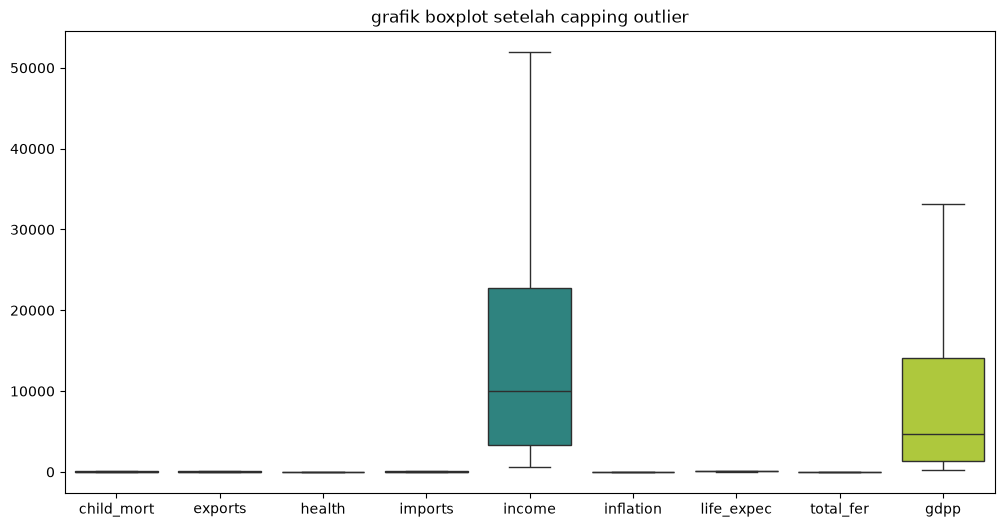

In [14]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, palette='viridis')
plt.title('grafik boxplot setelah capping outlier')
plt.show()

**Insight**: gafik menunjukan keseluruhan kolom telah bebas dari outlier dengan ditandai titik titik outlier yang menghilang seetalah capping.

### 4.3. Scalling kolom numerik dengan MinMaxScalling

Penggunaan metode MinMaxScaling diterapkan setelah proses capping IQR karena mampu menyetarakan seluruh variabel ke dalam rentang seragam 0 hingga 1 tanpa terdistorsi nilai ekstrem, sehingga fitur berskala besar seperti `income` dan `gdpp` tidak lagi mendominasi perhitungan jarak Euclidean pada tahap modeling.

In [15]:
X = df[numeric_cols].to_numpy(dtype=float)

X_scaled = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))

df_scaled = pd.DataFrame(X_scaled, columns=numeric_cols)

df_scaled.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,0.250210,0.426016,0.404758,0.451153,0.298151,0.397429,0.650756,0.306458,0.307617
std,0.274057,0.230120,0.216743,0.200364,0.296099,0.236340,0.245253,0.257032,0.352960
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.040278,0.255936,0.252640,0.296861,0.053467,0.212196,0.496403,0.110115,0.033405
50%,0.119052,0.376931,0.366369,0.425914,0.182073,0.338386,0.720863,0.215109,0.134624
75%,0.424167,0.553562,0.551584,0.578117,0.432080,0.527318,0.827338,0.466069,0.420043
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### 4.4 visualisasi setelah scalling

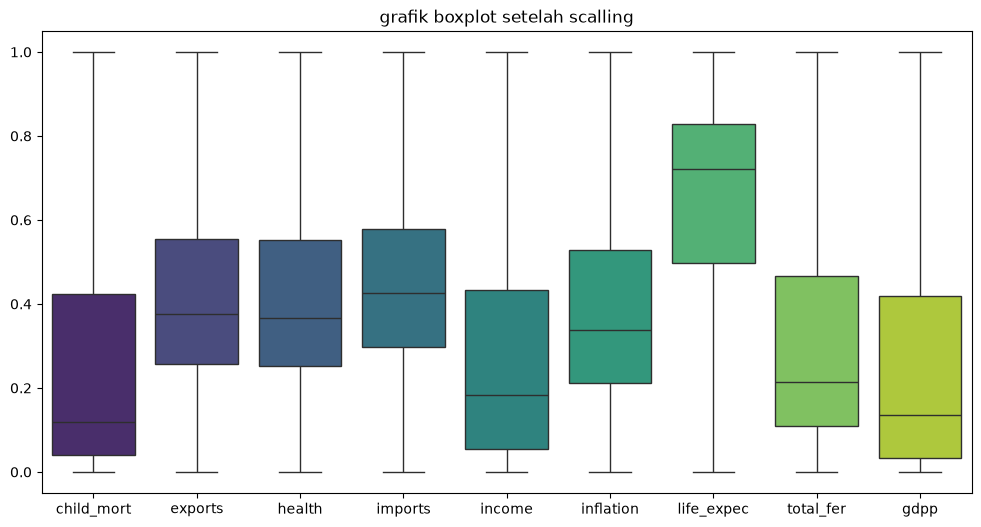

In [16]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_scaled, palette='viridis', whis=(0, 100))
plt.title('grafik boxplot setelah scalling')
plt.show()

**Insight**: Grafik boxplot setelah penyekalaan menunjukkan bahwa seluruh sembilan fitur numerik kini memiliki rentang nilai yang seragam pada skala 0,0 hingga 1,0 tanpa ada lagi titik outlier maupun variabel yang mendominasi tampilan grafik.

---

## 5. Modelling

### 5.1 Membangun Algoritma K-Means++ Clustering

In [ ]:
# Fungsi untuk menghitung jarak garis lurus (Euclidean Distance) antara dua titik
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

class KMeansPlusPlus:

    # Fungsi konstruktor yang otomatis berjalan pertama kali saat objek dibuat
    def __init__(self, K=3, max_iters=100, plot_steps=False, random_state=43):
        self.K = K
        self.max_iters = max_iters
        self.plot_steps = plot_steps
        self.random_state = random_state

        self.clusters = [[] for _ in range(self.K)]
        self.centroids = []
        self.labels = None

    # Fungsi inisialisasi centroid awal menggunakan strategi K-Means++
    def _init_centroids(self):
        if self.random_state is not None:
            np.random.seed(self.random_state)

        first_idx = np.random.randint(self.n_samples)
        centroids = [self.X[first_idx]]

        for _ in range(1, self.K):
            dist_sq = np.array([
                min([np.sum((x - c) ** 2) for c in centroids])
                for x in self.X
            ])

            sum_dist = dist_sq.sum()
            if sum_dist == 0:
                probs = np.ones(self.n_samples) / self.n_samples
            else:
                probs = dist_sq / sum_dist

            probs = probs / probs.sum()

            next_idx = np.random.choice(self.n_samples, p=probs)
            centroids.append(self.X[next_idx])

        return np.array(centroids)

    # Fungsi utama untuk memulai proses pengelompokan pada matriks fitur X
    def predict(self, X):
        self.X = np.nan_to_num(np.asarray(X, dtype=float))
        self.n_samples, self.n_features = self.X.shape

        self.centroids = self._init_centroids()

        for _ in range(self.max_iters):
            self.clusters = self._create_clusters(self.centroids)

            if self.plot_steps:
                self.plot()

            centroids_old = self.centroids
            self.centroids = self._get_centroids(self.clusters)

            if self._is_converged(centroids_old, self.centroids):
                break

            if self.plot_steps:
                self.plot()

        self.labels = self._get_cluster_labels(self.clusters)
        return self.labels

    # Fungsi untuk mengubah daftar indeks kelompok menjadi array label akhir yang urut
    def _get_cluster_labels(self, clusters):
        labels = np.empty(self.n_samples, dtype=int)
        for cluster_idx, cluster in enumerate(clusters):
            for sample_idx in cluster:
                labels[sample_idx] = cluster_idx
        return labels

    # Fungsi untuk mengelompokkan seluruh titik data ke dalam cluster dengan centroid terdekat
    def _create_clusters(self, centroids):
        clusters = [[] for _ in range(self.K)]
        for idx, sample in enumerate(self.X):
            centroid_idx = self._closest_centroid(sample, centroids)
            clusters[centroid_idx].append(idx)
        return clusters

    # Fungsi untuk mencari indeks centroid yang jaraknya paling dekat dengan satu sampel
    def _closest_centroid(self, sample, centroids):
        distances = [euclidean_distance(sample, point) for point in centroids]
        closest_idx = np.argmin(distances)
        return closest_idx

    # Fungsi untuk memperbarui posisi centroid ke nilai rata-rata kelompok terbaru
    def _get_centroids(self, clusters):
        centroids = np.zeros((self.K, self.n_features))
        for cluster_idx, cluster in enumerate(clusters):
            if len(cluster) > 0:
                cluster_mean = np.mean(self.X[cluster], axis=0)
                centroids[cluster_idx] = cluster_mean
            else:
                centroids[cluster_idx] = self.centroids[cluster_idx]
        return centroids

    # Fungsi untuk memeriksa apakah posisi centroid sudah tidak bergeser lagi
    def _is_converged(self, centroids_old, centroids):
        distances = [euclidean_distance(centroids_old[i], centroids[i]) for i in range(self.K)]
        return sum(distances) == 0

### 5.2 Menyiapkan Matrik Fitur dan Melatih Model

In [18]:
kmeans_pp = KMeansPlusPlus(K=3, max_iters=100, plot_steps=False, random_state=43)
cluster_labels = kmeans_pp.predict(X_scaled)

print(" Ukuran Matriks Input :", X_scaled.shape)
print(" Bentuk Koordinat Centroid Akhir :", kmeans_pp.centroids.shape)
print(" Contoh 10 Label Cluster Pertama :", cluster_labels[:10])

TypeError: 'numpy.int64' object is not callable

### 5.3 Menggabungkan Label Cluster

In [ ]:
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_labels

print("Jumlah Negara pada Setiap Cluster:")
print(df_clustered['Cluster'].value_counts().sort_index())

---

## 6. Evaluation

### 6.1 Menghitung Metrik Evaluasi Model (WCSS / SSE dan Silhouette Score)

In [ ]:
# Fungsi untuk menghitung Within-Cluster Sum of Squares (WCSS / SSE)
def hitung_wcss(X, labels, centroids):
    wcss = 0.0
    for i in range(len(centroids)):
        cluster_points = X[labels == i]
        if len(cluster_points) > 0:
            wcss += np.sum((cluster_points - centroids[i]) ** 2)
    return wcss

# Fungsi untuk menghitung Silhouette Score
def hitung_silhouette_score(X, labels):
    n_samples = len(X)
    unique_clusters = np.unique(labels)
    if len(unique_clusters) < 2:
        return 0.0

    dist_matrix = np.sqrt(np.sum((X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2, axis=2))

    silhouette_vals = np.zeros(n_samples)
    for i in range(n_samples):
        own_cluster = labels[i]
        mask_own = (labels == own_cluster)
        mask_own[i] = False

        if np.sum(mask_own) > 0:
            a_i = np.mean(dist_matrix[i, mask_own])
        else:
            a_i = 0.0

        b_i = np.inf
        for other_cluster in unique_clusters:
            if other_cluster != own_cluster:
                mask_other = (labels == other_cluster)
                if np.sum(mask_other) > 0:
                    mean_dist_other = np.mean(dist_matrix[i, mask_other])
                    if mean_dist_other < b_i:
                        b_i = mean_dist_other

        denom = max(a_i, b_i)
        silhouette_vals[i] = (b_i - a_i) / denom if denom > 0 else 0.0

    return np.mean(silhouette_vals)

wcss_utama = hitung_wcss(X_scaled, cluster_labels, kmeans_pp.centroids)
silhouette_utama = hitung_silhouette_score(X_scaled, cluster_labels)

print(f"Hasil Evaluasi Model K-Means++ (K = {kmeans_pp.K}):")
print(f"- Nilai WCSS / SSE   : {wcss_utama:.4f}")
print(f"- Silhouette Score   : {silhouette_utama:.4f}")

### 6.2 Evaluasi Perbandingan Jumlah Cluster (K = 1 - 10)

In [ ]:
k_range = range(1, 10)
wcss_list = []
silhouette_list = []

for k in k_range:
    model_uji = KMeansPlusPlus(K=k, max_iters=100, plot_steps=False, random_state=43)
    labels_uji = model_uji.predict(X_scaled)
    
    wcss_val = hitung_wcss(X_scaled, labels_uji, model_uji.centroids)
    wcss_list.append(wcss_val)
    
    if k >= 2:
        sil_val = hitung_silhouette_score(X_scaled, labels_uji)
        silhouette_list.append(sil_val)
    else:
        silhouette_list.append(np.nan)

df_evaluasi_k = pd.DataFrame({'Jumlah Cluster (K)': list(k_range), 'WCSS / SSE': np.round(wcss_list, 4), 'Silhouette Score': np.round(silhouette_list, 4)})
print("Tabel Perbandingan Evaluasi Nilai K:")
display(df_evaluasi_k)

### 6.3 Evaluasi Profil Karakteristik Cluster & Pemetaan Kategori Pembangunan Negara

In [ ]:
fitur_evaluasi = ['child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']

urutan_cluster_gdpp = df_clustered.groupby('Cluster')['gdpp'].mean().sort_values().index.tolist()

nama_kategori = ["Negara Prioritas Bantuan", "Negara Berkembang", "Negara Maju"]

cluster_label_map = {
    cluster_id: nama_kategori[idx] 
    for idx, cluster_id in enumerate(urutan_cluster_gdpp)
}

df_clustered['Kategori_Pembangunan'] = df_clustered['Cluster'].map(cluster_label_map)

print("Pemetaan Nomor Cluster ke Kategori Pembangunan:")
for cid, kategori in cluster_label_map.items():
    jumlah_negara = (df_clustered['Cluster'] == cid).sum()
    print(f"- Cluster {cid} ({jumlah_negara} negara) -> {kategori}")

profil_rata_rata = df_clustered.groupby(['Cluster', 'Kategori_Pembangunan'])[fitur_evaluasi].mean().round(2)
print("\nTabel Evaluasi Rata-Rata Indikator Sosio-Ekonomi & Kesehatan per Cluster:")
display(profil_rata_rata)